# Learning curve

How much does the XGBoost matcher improve with more labeled products? For each training size (100, 150, 200 products) and each of 10 random seeds, the model is trained on that many products and scored on a held-out test set of products it has never seen. The TF-IDF baseline gets the same treatment (its threshold is tuned on the same training sample).

With 281 labeled products and 20% held out for testing, 200 is the largest size that fits. "Labels" means labeled Coop products, each with its 10 candidate pairs.

In [1]:
# Setup: load normalized products, candidate pairs (from explore.ipynb) and labels (from labeler/)
import json
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

products = pd.read_parquet("../data/products_normalized.parquet")
candidate_pairs = pd.read_parquet("../data/candidate_pairs.parquet")

# dtype=str: otherwise pandas turns EAN codes into integers and drops leading zeros
labels = pd.read_json("../labels/labels.jsonl", lines=True, dtype={"coop_key": str})
labels = labels.drop_duplicates("coop_key", keep="last")  # latest answer wins if you relabeled

# The held-out test set (labels/split.json) stays out of everything here, it's only scored in match.ipynb
split = json.loads(Path("../labels/split.json").read_text())
labels = labels[~labels["order"].between(split["test_from_order"], split["test_to_order"] - 1)]
print(labels["status"].value_counts())

status
match    171
none     110
skip      20
Name: count, dtype: int64


In [2]:
# One row per (Coop product, shown ICA candidate), y = 1 if you selected it. Skipped products are left out.
labeled = labels[labels["status"].isin(["match", "none"])]
pairs = (
    labeled[["coop_key", "shown", "matches"]]
    .explode("shown")
    .rename(columns={"shown": "ica_key"})
    .merge(candidate_pairs[["coop_key", "ica_key", "rank", "score"]], on=["coop_key", "ica_key"], how="left")
)
pairs["y"] = [ica in matches for ica, matches in zip(pairs["ica_key"], pairs["matches"])]
pairs["y"] = pairs["y"].astype(int)
pairs = pairs.drop(columns="matches")

# If candidate_pairs was regenerated after labeling, some shown pairs may be missing a score
assert pairs["score"].notna().all(), "candidate_pairs.parquet changed since labeling"
print(f"{len(pairs):,} pairs, {pairs['y'].sum()} positives, {pairs['coop_key'].nunique()} Coop products")

2,810 pairs, 175 positives, 281 Coop products


In [3]:
# Pair features
INFO = ["product_key", "name", "brand_norm", "name_norm", "size_value", "size_unit", "price"]
coop_info = products[products["store"] == "coop"][INFO].add_prefix("coop_")
ica_info = products[products["store"] == "ica"][INFO].add_prefix("ica_")

def similarity(a, b):
    return SequenceMatcher(None, a, b).ratio()

def jaccard(a, b):
    a, b = set(a.split()), set(b.split())
    return len(a & b) / len(a | b) if a | b else 0.0

def add_features(df):
    df = (
        df.merge(coop_info, left_on="coop_key", right_on="coop_product_key")
          .merge(ica_info, left_on="ica_key", right_on="ica_product_key")
    )
    # How this candidate compares to the best TF-IDF candidate for the same Coop product
    df["score_gap"] = df.groupby("coop_key")["score"].transform("max") - df["score"]

    df["brand_equal"] = (df["coop_brand_norm"] == df["ica_brand_norm"]).astype(int)
    df["brand_sim"] = [similarity(a, b) for a, b in zip(df["coop_brand_norm"], df["ica_brand_norm"])]
    df["name_sim"] = [similarity(a, b) for a, b in zip(df["coop_name_norm"], df["ica_name_norm"])]
    df["name_jaccard"] = [jaccard(a, b) for a, b in zip(df["coop_name_norm"], df["ica_name_norm"])]

    # Size and price: NaN when unknown, xgboost handles missing values itself
    same_unit = df["coop_size_unit"] == df["ica_size_unit"]
    df["same_unit"] = np.where(df["coop_size_unit"].isna() | df["ica_size_unit"].isna(), np.nan, same_unit)
    sizes = df[["coop_size_value", "ica_size_value"]].where(same_unit, axis=0)
    df["size_ratio"] = sizes.min(axis=1) / sizes.max(axis=1)
    prices = df[["coop_price", "ica_price"]]
    df["price_ratio"] = prices.min(axis=1) / prices.max(axis=1)
    return df

FEATURES = [
    "score", "rank", "score_gap",
    "brand_equal", "brand_sim", "name_sim", "name_jaccard",
    "same_unit", "size_ratio", "price_ratio",
]

pairs = add_features(pairs)

In [4]:
# Product-level evaluation: per Coop product, take the best candidate if its score >= threshold, else "none".
# precision = predicted matches that are right, recall = real matches found,
# accuracy = products fully right (a "none" product counts as right when nothing is predicted)
def evaluate(df, score_col, threshold):
    # ties (e.g. ICA duplicates with the same score) go to the better TF-IDF rank
    best = df.sort_values([score_col, "rank"], ascending=[False, True]).groupby("coop_key").head(1)
    has_match = df.groupby("coop_key")["y"].max()
    predicted = best[best[score_col] >= threshold]

    correct = predicted["y"].sum()
    n_predicted, n_real = len(predicted), has_match.sum()
    n_correct_none = ((has_match == 0) & ~has_match.index.isin(predicted["coop_key"])).sum()
    return {
        "precision": correct / n_predicted if n_predicted else 0.0,
        "recall": correct / n_real,
        "accuracy": (correct + n_correct_none) / len(has_match),
        "threshold": threshold,
    }

def best_threshold(df, score_col, metric="accuracy"):
    results = [evaluate(df, score_col, t) for t in np.arange(0, 1.0, 0.05)]
    return max(results, key=lambda r: r[metric])

In [5]:
# Learning curve: train on N labeled products, test on a held-out set, repeat with 10 seeds.
# Each seed draws its own test set (20% of products, stratified on has-a-match, never used for training).
# Within a seed the training sets are nested (100 is a subset of 150, which is a subset of 200)
# and every size is scored on the same test set, so the sizes are compared like with like.
TRAIN_SIZES = [100, 150, 200]
SEEDS = range(10)
TEST_SIZE = 0.2
THRESHOLD = 0.5
METRICS = ["precision", "recall", "accuracy"]

def make_model():
    return XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=0)

has_match = pairs.groupby("coop_key")["y"].max()
coop_keys = has_match.index.to_numpy()

rows = []
for seed in SEEDS:
    pool, test = train_test_split(coop_keys, test_size=TEST_SIZE, stratify=has_match, random_state=seed)
    assert len(pool) >= max(TRAIN_SIZES), f"only {len(pool)} products left for training, need {max(TRAIN_SIZES)}"
    test_pairs = pairs[pairs["coop_key"].isin(test)]
    order = np.random.default_rng(seed).permutation(pool)

    for n in TRAIN_SIZES:
        train_pairs = pairs[pairs["coop_key"].isin(order[:n])]

        model = make_model().fit(train_pairs[FEATURES], train_pairs["y"])
        scored = test_pairs.assign(prob=model.predict_proba(test_pairs[FEATURES])[:, 1])
        rows.append({"seed": seed, "n_train": n, "model": "XGBoost", **evaluate(scored, "prob", THRESHOLD)})

        # Baseline: the TF-IDF threshold is tuned on the same training sample, then applied to the test set
        baseline_threshold = best_threshold(train_pairs, "score")["threshold"]
        rows.append({"seed": seed, "n_train": n, "model": "TF-IDF baseline", **evaluate(test_pairs, "score", baseline_threshold)})

results = pd.DataFrame(rows)
print(f"{len(coop_keys)} labeled products, {len(test)} in each test set, {len(results)} runs")

281 labeled products, 57 in each test set, 60 runs


In [6]:
# Mean and standard deviation across the 10 seeds
summary = results.groupby(["model", "n_train"])[METRICS].agg(["mean", "std"]).round(3)
summary

precision        recall        accuracy       
                             mean    std   mean    std     mean    std
model           n_train                                               
TF-IDF baseline 100         0.655  0.049  0.660  0.065    0.704  0.037
                150         0.660  0.035  0.663  0.068    0.705  0.035
                200         0.660  0.035  0.657  0.074    0.704  0.036
XGBoost         100         0.897  0.036  0.691  0.083    0.777  0.055
                150         0.877  0.032  0.729  0.090    0.795  0.063
                200         0.886  0.029  0.746  0.100    0.805  0.062

In [7]:
# Paired change from the smallest to the largest training size: same seed, so same test set at both sizes
first, last = TRAIN_SIZES[0], TRAIN_SIZES[-1]
wide = results[results["model"] == "XGBoost"].pivot(index="seed", columns="n_train", values=METRICS)
gain = pd.DataFrame({m: wide[m][last] - wide[m][first] for m in METRICS})
pd.DataFrame({"mean gain": gain.mean(), "sd": gain.std(), "seeds improved": (gain > 0).sum()}).round(3)

,mean gain,sd,seeds improved
precision,-0.011,0.034,3
recall,0.054,0.049,8
accuracy,0.028,0.022,9


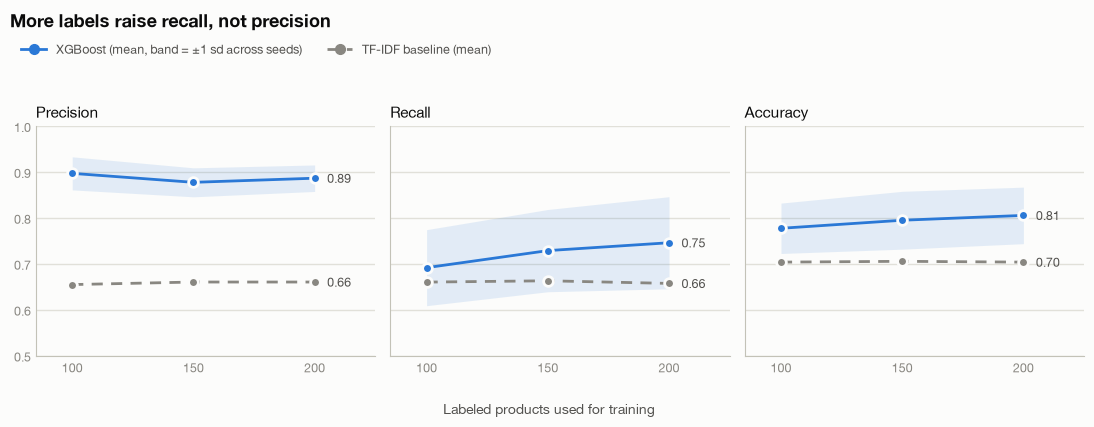

In [8]:
# Chart tokens (light surface): one data hue for the model, neutral gray for the baseline
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
XGB_COLOR, BASELINE_COLOR = "#2a78d6", "#898781"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica Neue", "Arial", "DejaVu Sans"]

stats = results.groupby(["model", "n_train"])[METRICS].agg(["mean", "std"])

fig, axes = plt.subplots(1, 3, figsize=(11, 4.2), sharey=True, facecolor=SURFACE)
for ax, metric in zip(axes, METRICS):
    xgb, base = stats.loc["XGBoost"][metric], stats.loc["TF-IDF baseline"][metric]
    ax.set_facecolor(SURFACE)

    ax.fill_between(xgb.index, xgb["mean"] - xgb["std"], xgb["mean"] + xgb["std"], color=XGB_COLOR, alpha=0.12, linewidth=0)
    ax.plot(base.index, base["mean"], color=BASELINE_COLOR, lw=2, ls=(0, (4, 3)), marker="o", ms=7, mec=SURFACE, mew=2)
    ax.plot(xgb.index, xgb["mean"], color=XGB_COLOR, lw=2, marker="o", ms=7, mec=SURFACE, mew=2)

    # Label only the last point of each line
    for series in (xgb, base):
        ax.annotate(f"{series['mean'].iloc[-1]:.2f}", (series.index[-1], series["mean"].iloc[-1]),
                    xytext=(9, 0), textcoords="offset points", va="center", fontsize=9, color=INK_2)

    ax.set_title(metric.capitalize(), loc="left", fontsize=11, color=INK)
    ax.set_xticks(TRAIN_SIZES)
    ax.set_xlim(TRAIN_SIZES[0] - 15, TRAIN_SIZES[-1] + 25)
    ax.set_ylim(0.5, 1.0)
    ax.grid(axis="y", color=GRID, lw=1)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)

legend_handles = [
    plt.Line2D([], [], color=XGB_COLOR, lw=2, marker="o", ms=7, label="XGBoost (mean, band = \u00b11 sd across seeds)"),
    plt.Line2D([], [], color=BASELINE_COLOR, lw=2, ls=(0, (4, 3)), marker="o", ms=7, label="TF-IDF baseline (mean)"),
]
fig.suptitle("More labels raise recall, not precision", x=0.01, ha="left", fontsize=13, color=INK, fontweight="bold")
fig.legend(handles=legend_handles, loc="upper left", bbox_to_anchor=(0.01, 0.93), ncol=2, frameon=False, fontsize=9, labelcolor=INK_2)
fig.supxlabel("Labeled products used for training", fontsize=10, color=INK_2)
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()